# Bagging Exercises

![Bagging.png](Assets/Bagging.png)

# Цели обучения

- Установить связь между понятиями «бутстреппинга» и «агрегирования» (более известного как «баггинг») для снижения дисперсии
- Применять алгоритм «Случайного леса», который позволяет ещё больше снизить корреляцию, наблюдаемую в моделях, построенных методом баггинга


## Введение

Для выполнения заданий на этой неделе мы будем использовать данные об оттоке клиентов из телекоммуникационной отрасли, которые мы рассматривали на первой неделе. Файл данных называется `Orange_Telecom_Churn_Data.csv`.

In [80]:
from __future__ import print_function
import os
data_path = [ 'data']

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix



## Вопрос 1

* Импортируйте данные об оттоке клиентов, содержащиеся в файле `Orange_Telecom_Churn_Data.csv`.
* Удалите все столбцы, которые, вероятно, не будут использоваться для прогнозирования.
* Осуществите соответствующее кодирование типов данных.

В прогнозе ни в коем случае не должно фигурировать номер телефона. И вряд ли потребуются код города или штат, если только нет оснований полагать, что модель учитывает какой-то очень конкретный географический фактор.

Проанализируйте типы данных. Всё выглядит нормально, за исключением того, что `int_plan` и `voice_mail_plan` необходимо кодировать как булевы значения.

In [81]:
# Импорт данных из файла Orange_Telecom_Churn_Data.csv
import pandas as pd

filepath = os.sep.join(data_path + ['Orange_Telecom_Churn_Data.csv'])
data = pd.read_csv(filepath)

In [82]:
# Удаление столбцов, которые не используются для прогнозирования
data.drop(['state', 'area_code', 'phone_number'], axis=1, inplace=True)

In [83]:
# Кодирование intl_plan и voice_mail_plan как булевых значений
for col in ['intl_plan', 'voice_mail_plan']:
    data[col] = data[col].map({'yes': True, 'no': False})

## Вопрос 2

* Проанализируйте распределение прогнозируемой переменной (`churned`).
* Разделите данные на обучающую и тестовую выборки. На основании распределения решите, следует ли использовать стратифицированное деление.
* Проанализируйте распределение предикторной переменной в обучающих и тестовых данных.

Учитывая асимметрию переменной-предиктора, давайте разбиваем данные, стратифицировав значения *churned*.

In [84]:
# Распределение прогнозируемой переменной churned
data.churned.value_counts(normalize=True)

churned
False    0.8586
True     0.1414
Name: proportion, dtype: float64

In [85]:
# Стратифицированное разделение на обучающую и тестовую выборки
feature_cols = [x for x in data.columns if x != 'churned']

strat_shuff_split = StratifiedShuffleSplit(n_splits=1, test_size=1500, random_state=42)
train_idx, test_idx = next(strat_shuff_split.split(data[feature_cols], data['churned']))

X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'churned']

X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'churned']

# Распределение churned в обучающей и тестовой выборках
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

churned
False    0.858571
True     0.141429
Name: proportion, dtype: float64
churned
False    0.858667
True     0.141333
Name: proportion, dtype: float64


## Вопрос 3

* Постройте модели «случайного леса» с различным количеством деревьев и оцените ошибку «out-of-bag» для каждой из этих моделей.
* Постройте график полученных ошибок «out-of-bag» в зависимости от количества деревьев.

*Подсказка:* поскольку изменяется только количество деревьев, можно использовать флаг `warm_start`, чтобы модель каждый раз просто добавляла новые деревья к существующей модели. Для обновления количества деревьев используйте метод `set_params`.

In [86]:
# Suppress warnings about too few trees from the early models

import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

Похоже, что количество ошибок стабилизировалось на уровне 100–150 деревьев.

In [87]:
# Модели случайного леса с разным количеством деревьев и ошибка out-of-bag
RF = RandomForestClassifier(oob_score=True, random_state=42, warm_start=True, n_jobs=-1)

oob_list = []
for n_trees in [15, 20, 30, 40, 50, 100, 150, 200, 300, 400]:
    RF.set_params(n_estimators=n_trees)
    RF.fit(X_train, y_train)
    oob_error = 1 - RF.oob_score_
    oob_list.append({'n_trees': n_trees, 'oob': oob_error})

rf_oob_df = pd.DataFrame(oob_list).set_index('n_trees')
rf_oob_df

,oob
n_trees,
15,0.059714
20,0.053429
30,0.049714
40,0.047429
50,0.049143
100,0.045143
150,0.045143
200,0.044857
300,0.044286


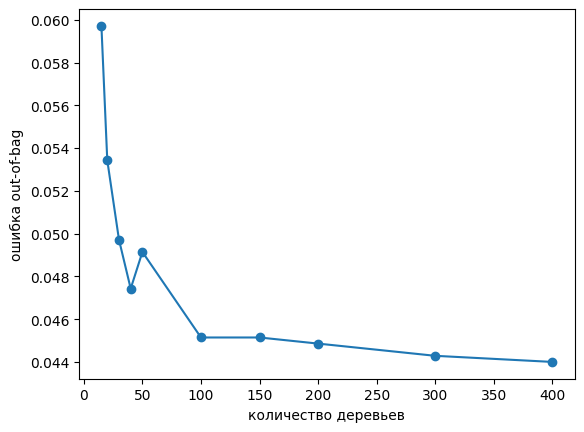

In [88]:
# График ошибки out-of-bag в зависимости от количества деревьев
import matplotlib.pyplot as plt

ax = rf_oob_df.plot(legend=False, marker='o')
ax.set(xlabel='количество деревьев', ylabel='ошибка out-of-bag')
plt.show()

## Вопрос 4

* Повторите задание из вопроса 3, используя дополнительные рандомизированные деревья (`ExtraTreesClassifier`). Обратите внимание, что для этой модели параметр `bootstrap` необходимо установить в значение `True`.
* Сравните ошибки метода «out-of-bag» для двух различных типов моделей.

Объедините два датафрейма в один, чтобы упростить построение графиков.

Модель «случайного леса» демонстрирует стабильно более высокую эффективность по сравнению с моделью «дополнительных рандомизированных деревьев».

In [89]:
# Модели дополнительных рандомизированных деревьев с разным количеством деревьев и ошибка out-of-bag
EF = ExtraTreesClassifier(oob_score=True, random_state=42, warm_start=True, bootstrap=True, n_jobs=-1)

oob_list = []
for n_trees in [15, 20, 30, 40, 50, 100, 150, 200, 300, 400]:
    EF.set_params(n_estimators=n_trees)
    EF.fit(X_train, y_train)
    oob_error = 1 - EF.oob_score_
    oob_list.append({'n_trees': n_trees, 'oob': oob_error})

et_oob_df = pd.DataFrame(oob_list).set_index('n_trees')
et_oob_df

,oob
n_trees,
15,0.080857
20,0.072000
30,0.069429
40,0.064286
50,0.067429
100,0.062857
150,0.061143
200,0.062571
300,0.060286


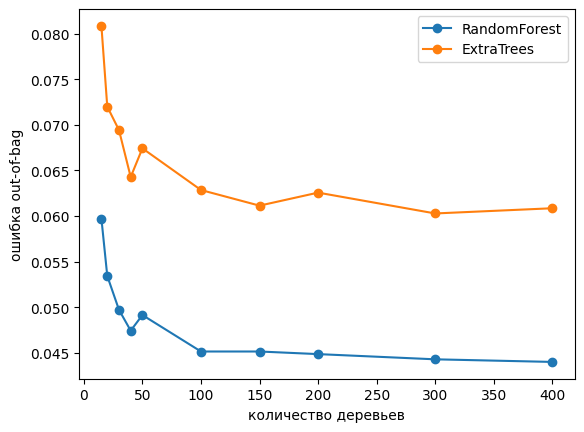

In [90]:
# Объединение ошибок out-of-bag двух моделей и сравнение на графике
oob_df = pd.concat([rf_oob_df.rename(columns={'oob': 'RandomForest'}),
                    et_oob_df.rename(columns={'oob': 'ExtraTrees'})], axis=1)

ax = oob_df.plot(marker='o')
ax.set(xlabel='количество деревьев', ylabel='ошибка out-of-bag')
plt.show()

## Вопрос 5

* Выберите одну из моделей, демонстрирующих хорошие результаты, и рассчитайте показатели ошибок и матрицу путаницы на тестовом наборе данных.
* Учитывая распределение предсказанных классов, какой показатель является наиболее важным? А какой может вводить в заблуждение?

Неудивительно, что показатель воспроизведения для класса «Ушедшие клиенты» (True) довольно низкий, поскольку их количество весьма невелико. Тем не менее, мы показываем лучшие результаты, чем при случайном угадывании: точность составляет 0,932 (против 0,85 при случайном угадывании).

In [91]:
# Выбор модели и расчёт показателей ошибок и матрицы путаницы на тестовом наборе
model = RF
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

score_df = pd.DataFrame({'accuracy': accuracy_score(y_test, y_pred),
                         'precision': precision_score(y_test, y_pred),
                         'recall': recall_score(y_test, y_pred),
                         'f1': f1_score(y_test, y_pred),
                         'auc': roc_auc_score(y_test, y_pred)},
                        index=pd.Index([0]))
print(score_df)

cm = confusion_matrix(y_test, y_pred)
print(cm)

              precision    recall  f1-score   support

       False       0.96      0.99      0.98      1288
        True       0.95      0.77      0.85       212

    accuracy                           0.96      1500
   macro avg       0.96      0.88      0.91      1500
weighted avg       0.96      0.96      0.96      1500

   accuracy  precision    recall        f1      auc
0  0.961333   0.947674  0.768868  0.848958  0.88094
[[1279    9]
 [  49  163]]


Так как ушедших клиентов (True) всего около 14% (212 из 1500), самый важный показатель — recall и f1 для класса True. Accuracy может вводить в заблуждение: у модели она 0,96, но и модель, которая всегда предсказывает «не ушёл», получила бы 0,86. При этом recall для True — 0,77, то есть 49 из 212 ушедших клиентов модель не нашла.

## Вопрос 6

* Распечатайте или отобразите матрицу путаницы.
* Постройте кривые ROC-AUC и точность-воспроизводимость.
* Постройте график важности признаков.

Кривые ROC-AUC и «точность-охватываемость».

Важность признаков. Общая ежедневная стоимость является наиболее значимым предиктором оттока клиентов.

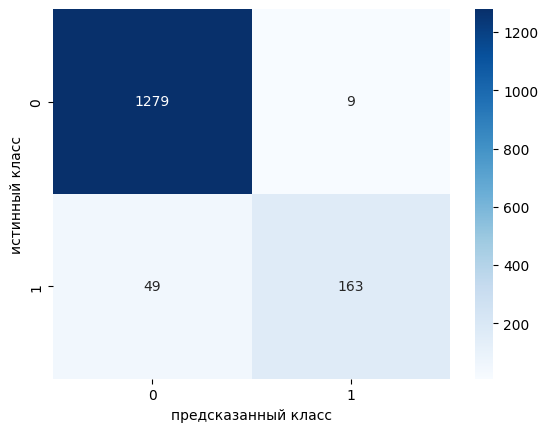

In [92]:
# Матрица путаницы
import seaborn as sns

ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
ax.set(xlabel='предсказанный класс', ylabel='истинный класс')
plt.show()

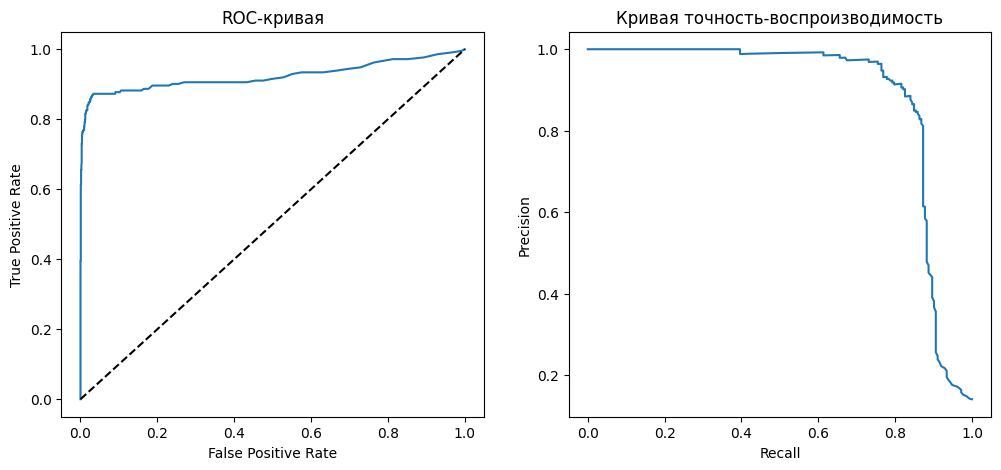

In [93]:
# Кривые ROC-AUC и точность-воспроизводимость
y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_prob)
precision, recall, _ = precision_recall_curve(y_test, y_prob)

fig, axList = plt.subplots(ncols=2, figsize=(12, 5))

ax = axList[0]
ax.plot(fpr, tpr)
ax.plot([0, 1], [0, 1], ls='--', color='black')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC-кривая')

ax = axList[1]
ax.plot(recall, precision)
ax.set(xlabel='Recall', ylabel='Precision', title='Кривая точность-воспроизводимость')

plt.show()

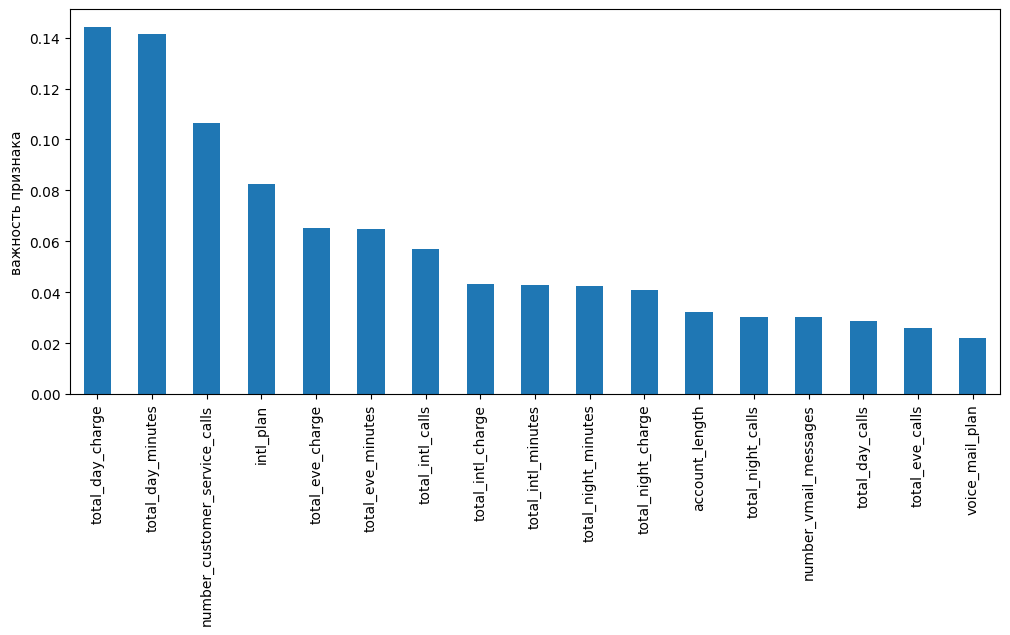

In [94]:
# График важности признаков
feature_imp = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False)

ax = feature_imp.plot(kind='bar', figsize=(12, 5))
ax.set(ylabel='важность признака')
plt.show()